# UrbanPulse Nepal — Geographic DBSCAN Comparison

This notebook compares DBSCAN settings for identifying spatially dense groups in the retrieved incident points. It uses great-circle distance through the Haversine metric, keeps the distinction between clusters and noise, and reports cluster counts, noise share, size distribution, and a sampled silhouette score where defined.

## Interpretation and limitations

The first comparison uses all incidents in the saved snapshot together, so it describes the spatial density of historical records across the retrieved period. It does not estimate future danger or risk. Reporting changes, repeated incidents in the same places, and unverified historical coverage can affect the clusters. Noise means points not assigned to a DBSCAN dense group at a particular configuration; it does not mean an incident is unimportant. Compare the configurations before deciding what should be analyzed further.

## 1. Load and prepare coordinates

DBSCAN expects coordinates in `[latitude, longitude]` order when using Haversine. The source GeoJSON is `[longitude, latitude]`, so the prepared feature array is deliberately reordered and converted to radians.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').is_dir(): PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'data').is_dir(): raise FileNotFoundError('Run from the repository or notebooks/ folder.')
PROCESSED_ROOT = PROJECT_ROOT / 'data' / 'processed' / 'bipad_incidents'
candidate_dirs = sorted((p for p in PROCESSED_ROOT.iterdir() if (p / 'incidents_processed.csv').is_file() and (p / 'data_quality_report.json').is_file()), key=lambda p:p.name)
if not candidate_dirs: raise FileNotFoundError(f'Run notebook 02 first; no processed data found under {PROCESSED_ROOT}')
DATA_DIR = candidate_dirs[-1]
df = pd.read_csv(DATA_DIR / 'incidents_processed.csv', low_memory=False)
quality = json.loads((DATA_DIR / 'data_quality_report.json').read_text(encoding='utf-8'))
if not {'id','latitude','longitude'}.issubset(df.columns): raise ValueError('Processed file must include id, latitude, and longitude.')
valid = np.isfinite(df['latitude'].to_numpy(dtype=float)) & np.isfinite(df['longitude'].to_numpy(dtype=float))
geo_df = df.loc[valid].copy().reset_index(drop=True)
if geo_df.empty: raise ValueError('No valid coordinate pairs are available for DBSCAN.')
EARTH_RADIUS_KM = 6371.0088
coords_radians = np.radians(geo_df[['latitude','longitude']].to_numpy(dtype=float))
print('Prepared dataset:', DATA_DIR)
print(f'Rows available: {len(df):,}; valid coordinate pairs: {len(geo_df):,}')
print('Source coverage complete:', quality.get('quality_audit',{}).get('pagination_complete'))
print('Coordinates are [latitude, longitude] radians for the Haversine distance.')

Prepared dataset: c:\Projects_Tracking\DisasterLens Nepal\data\processed\bipad_incidents\20261013T101245Z
Rows available: 64,735; valid coordinate pairs: 64,735
Source coverage complete: False
Coordinates are [latitude, longitude] radians for the Haversine distance.


## 2. Compare distance and minimum-sample settings

`eps_km` is the neighborhood radius: smaller values find only tighter concentrations, while larger values can combine nearby places. `min_samples` is the number of records required to form a dense neighborhood. These settings are exploratory alternatives, not universally meaningful thresholds. The silhouette score is calculated on a reproducible sample of clustered points only (noise excluded); it is omitted if fewer than two sampled clusters are available.

In [2]:
CONFIGS = [
    {'eps_km':0.5, 'min_samples':5},
    {'eps_km':1.0, 'min_samples':5},
    {'eps_km':2.0, 'min_samples':5},
    {'eps_km':5.0, 'min_samples':5},
    {'eps_km':1.0, 'min_samples':10},
]
SILHOUETTE_SAMPLE_SIZE = 1500
rows, label_columns = [], {}
for config in CONFIGS:
    eps_km, min_samples = config['eps_km'], config['min_samples']
    model = DBSCAN(eps=eps_km / EARTH_RADIUS_KM, min_samples=min_samples, metric='haversine', algorithm='ball_tree', n_jobs=-1)
    labels = model.fit_predict(coords_radians)
    label_col = f'labels_eps{eps_km:g}km_min{min_samples}'
    label_columns[label_col] = labels
    cluster_ids, cluster_sizes = np.unique(labels[labels >= 0], return_counts=True)
    noise_count = int(np.sum(labels == -1))
    clustered_positions = np.flatnonzero(labels >= 0)
    silhouette = np.nan
    if len(cluster_ids) >= 2 and len(clustered_positions) > len(cluster_ids):
        sample_n = min(SILHOUETTE_SAMPLE_SIZE, len(clustered_positions))
        rng = np.random.default_rng(42)
        selected = rng.choice(clustered_positions, size=sample_n, replace=False)
        sample_labels = labels[selected]
        if len(np.unique(sample_labels)) >= 2 and len(selected) > len(np.unique(sample_labels)):
            try: silhouette = float(silhouette_score(coords_radians[selected], sample_labels, metric='haversine'))
            except ValueError: silhouette = np.nan
    rows.append({'eps_km':eps_km, 'min_samples':min_samples, 'clusters_excluding_noise':len(cluster_ids), 'noise_points':noise_count, 'noise_percent':100*noise_count/len(labels), 'largest_cluster_size':int(cluster_sizes.max()) if len(cluster_sizes) else 0, 'median_cluster_size':float(np.median(cluster_sizes)) if len(cluster_sizes) else 0, 'smallest_cluster_size':int(cluster_sizes.min()) if len(cluster_sizes) else 0, 'sampled_clustered_point_silhouette_haversine':silhouette})
    print(f'Finished eps={eps_km:g} km, min_samples={min_samples}')

results = pd.DataFrame(rows)
display(results)

Finished eps=0.5 km, min_samples=5
Finished eps=1 km, min_samples=5
Finished eps=2 km, min_samples=5
Finished eps=5 km, min_samples=5
Finished eps=1 km, min_samples=10


,eps_km,min_samples,clusters_excluding_noise,noise_points,noise_percent,largest_cluster_size,median_cluster_size,smallest_cluster_size,sampled_clustered_point_silhouette_haversine
0,0.5,5,3129,7956,12.290106,1244,8.0,5,0.632343
1,1.0,5,3039,7724,11.931722,1244,8.0,5,0.623676
2,2.0,5,2573,5889,9.097088,3419,8.0,5,0.577977
3,5.0,5,298,640,0.988646,38428,10.0,5,-0.527638
4,1.0,10,1019,21030,32.486290,1244,13.0,10,0.779292


## 3. Review sensitivity and select a configuration for follow-up

Read the number of clusters together with the noise share and cluster sizes. A score is only one diagnostic: evaluate geographic coherence and compare the results under different settings before interpreting any cluster. This notebook does not automatically declare a winning configuration.

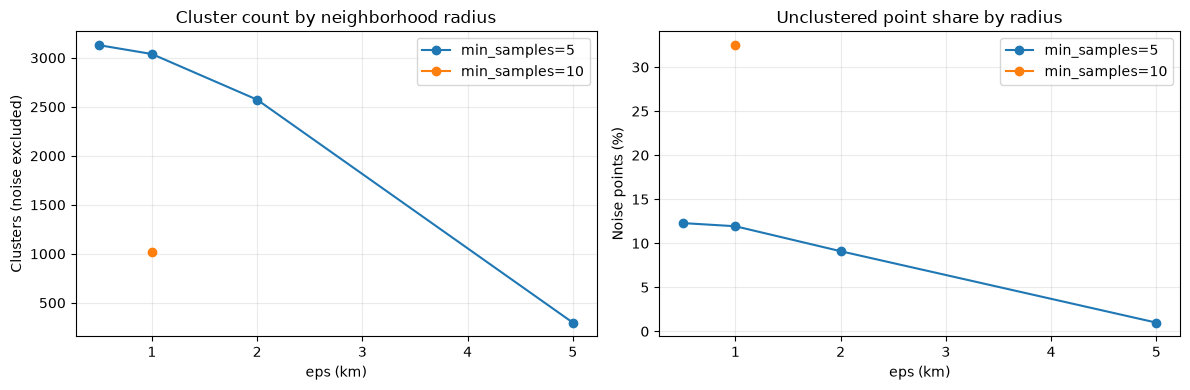

,eps_km,min_samples,clusters_excluding_noise,noise_percent,smallest_cluster_size,median_cluster_size,largest_cluster_size,sampled_clustered_point_silhouette_haversine
0,0.5,5,3129,12.290106,5,8.0,1244,0.632343
1,1.0,5,3039,11.931722,5,8.0,1244,0.623676
2,2.0,5,2573,9.097088,5,8.0,3419,0.577977
3,5.0,5,298,0.988646,5,10.0,38428,-0.527638
4,1.0,10,1019,32.486290,10,13.0,1244,0.779292


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for min_samples, group in results.groupby('min_samples'):
    axes[0].plot(group['eps_km'], group['clusters_excluding_noise'], marker='o', label=f'min_samples={min_samples}')
    axes[1].plot(group['eps_km'], group['noise_percent'], marker='o', label=f'min_samples={min_samples}')
axes[0].set(title='Cluster count by neighborhood radius', xlabel='eps (km)', ylabel='Clusters (noise excluded)')
axes[1].set(title='Unclustered point share by radius', xlabel='eps (km)', ylabel='Noise points (%)')
for ax in axes: ax.grid(alpha=0.25); ax.legend()
plt.tight_layout(); plt.show()

size_summary = results[['eps_km','min_samples','clusters_excluding_noise','noise_percent','smallest_cluster_size','median_cluster_size','largest_cluster_size','sampled_clustered_point_silhouette_haversine']]
display(size_summary)

## 4. Save labels and comparison results

The files below preserve each tested configuration’s point label alongside its incident ID. A label of `-1` means the point was noise for that particular configuration. Configuration labels are not comparable across separate model fits as stable cluster identities.

In [4]:
OUTPUT_DIR = PROJECT_ROOT / 'data' / 'processed' / 'dbscan' / DATA_DIR.name
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
labels_df = pd.DataFrame({'id':geo_df['id'].astype('string'), 'latitude':geo_df['latitude'], 'longitude':geo_df['longitude'], **label_columns})
labels_path = OUTPUT_DIR / 'dbscan_labels.csv'
results_path = OUTPUT_DIR / 'dbscan_configuration_comparison.csv'
labels_df.to_csv(labels_path, index=False, encoding='utf-8-sig')
results.to_csv(results_path, index=False, encoding='utf-8-sig')
print('Labels:', labels_path)
print('Configuration comparison:', results_path)
print('Interpret all clusters as spatial groupings in historical reporting, not forecasts or future danger zones.')

Labels: c:\Projects_Tracking\DisasterLens Nepal\data\processed\dbscan\20261013T101245Z\dbscan_labels.csv
Configuration comparison: c:\Projects_Tracking\DisasterLens Nepal\data\processed\dbscan\20261013T101245Z\dbscan_configuration_comparison.csv
Interpret all clusters as spatial groupings in historical reporting, not forecasts or future danger zones.


## Findings from the executed DBSCAN comparison

The saved run analyzed **64,735 points**. All five configurations produced clusters, but the results changed substantially with the distance radius and minimum neighborhood count:

| eps | min_samples | Clusters | Noise points | Noise | Largest cluster | Median cluster size | Sampled silhouette* |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.5 km | 5 | 3,129 | 7,956 | 12.29% | 1,244 | 8 | 0.632 |
| 1 km | 5 | 3,039 | 7,724 | 11.93% | 1,244 | 8 | 0.624 |
| 2 km | 5 | 2,573 | 5,889 | 9.10% | 3,419 | 8 | 0.578 |
| 5 km | 5 | 298 | 640 | 0.99% | 38,428 | 10 | -0.528 |
| 1 km | 10 | 1,019 | 21,030 | 32.49% | 1,244 | 13 | 0.779 |

The 5 km radius merges most incidents into a very large cluster and has a negative sampled silhouette, indicating a poor fit to the sampled clustered-point geometry. The 1 km, 10-sample setting has the highest sampled silhouette, but it leaves nearly one-third of the points as noise. The 0.5–2 km settings yield thousands of small clusters, with median sizes of 8 and lower noise shares as the radius increases. These are different trade-offs, not a clear automatic winner.

*The silhouette values were computed on a reproducible sample of up to 1,500 clustered points; noise points were excluded. They should not be compared as if they were a complete quality score for all incidents, and a high score does not establish geographic usefulness. The run considered incidents across the full retrieved period, whose historical coverage is unverified. These clusters describe the density of recorded historical locations only; they do not identify future danger zones.*